In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.ensemble import IsolationForest
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report

In [2]:
PROJECT_ROOT = Path.cwd().parent

DATA_FILE = (
    PROJECT_ROOT
    / "data"
    / "raw"
    / "cmapss"
    / "train_FD001.txt"
)

columns = [
    "unit_id",
    "cycle",
    "op_setting_1",
    "op_setting_2",
    "op_setting_3"
]

sensor_columns = [
    f"sensor_{i}"
    for i in range(1, 22)
]

columns += sensor_columns

df = pd.read_csv(
    DATA_FILE,
    sep=r"\s+",
    header=None,
    names=columns
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of engines:", df["unit_id"].nunique())

df.head()

Dataset loaded successfully!
Dataset shape: (20631, 26)
Number of engines: 100


,unit_id,cycle,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,522.86,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,522.19,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044


In [3]:
print("Dataset shape:", df.shape)
print("First 5 engine IDs:", df["unit_id"].unique()[:5])
print("Last 5 engine IDs:", df["unit_id"].unique()[-5:])
print("Number of unique engines:", df["unit_id"].nunique())
print("Missing values:", df.isnull().sum().sum())

Dataset shape: (20631, 26)
First 5 engine IDs: [1 2 3 4 5]
Last 5 engine IDs: [ 96  97  98  99 100]
Number of unique engines: 100
Missing values: 0


In [4]:
sensor_features = sensor_columns

X = df[sensor_features]

print("Sensor features selected:", len(sensor_features))
print("Input data shape:", X.shape)
print("Missing sensor values:", X.isnull().sum().sum())

Sensor features selected: 21
Input data shape: (20631, 21)
Missing sensor values: 0


In [5]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

print("Sensor scaling completed!")
print("Scaled data shape:", X_scaled.shape)
print("Mean of first sensor:", round(X_scaled[:, 0].mean(), 4))
print("Standard deviation of first sensor:", round(X_scaled[:, 0].std(), 4))

Sensor scaling completed!
Scaled data shape: (20631, 21)
Mean of first sensor: 0.0
Standard deviation of first sensor: 0.0


In [6]:
print("Original sensor standard deviations:")
print(X.std().head(10))

print("\nScaled sensor standard deviations:")
print(np.round(X_scaled.std(axis=0), 4)[:10])

Original sensor standard deviations:
sensor_1     0.000000e+00
sensor_2     5.000533e-01
sensor_3     6.131150e+00
sensor_4     9.000605e+00
sensor_5     5.329200e-15
sensor_6     1.388985e-03
sensor_7     8.850923e-01
sensor_8     7.098548e-02
sensor_9     2.208288e+01
sensor_10    0.000000e+00
dtype: float64

Scaled sensor standard deviations:
[0. 1. 1. 1. 0. 1. 1. 1. 1. 0.]


In [7]:
# Identify sensors with meaningful variation
sensor_std = X.std()

useful_sensors = sensor_std[sensor_std > 1e-8].index.tolist()

# Select only useful sensor features
X_useful = df[useful_sensors]

print("Original number of sensors:", len(sensor_columns))
print("Useful sensors selected:", len(useful_sensors))
print("Removed sensors:", sorted(set(sensor_columns) - set(useful_sensors)))
print("Useful sensor data shape:", X_useful.shape)

Original number of sensors: 21
Useful sensors selected: 15
Removed sensors: ['sensor_1', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19', 'sensor_5']
Useful sensor data shape: (20631, 15)


In [8]:
# Scale the selected sensor features
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_useful)

print("Scaling completed successfully!")
print("Scaled data shape:", X_scaled.shape)
print("Mean of first sensor:", round(X_scaled[:, 0].mean(), 4))
print("Standard deviation of first sensor:", round(X_scaled[:, 0].std(), 4))

Scaling completed successfully!
Scaled data shape: (20631, 15)
Mean of first sensor: 0.0
Standard deviation of first sensor: 1.0


In [10]:
# Split data by engine to avoid mixing engines between sets
train_engines = list(range(1, 81))
eval_engines = list(range(81, 101))

train_df = df[df["unit_id"].isin(train_engines)].copy()
eval_df = df[df["unit_id"].isin(eval_engines)].copy()

# Use the first 30 cycles of each training engine as a baseline
baseline_df = (
    train_df[train_df["cycle"] <= 30]
    .copy()
)

print("Training engines:", train_df["unit_id"].nunique())
print("Evaluation engines:", eval_df["unit_id"].nunique())
print("Baseline observations:", len(baseline_df))
print("Baseline engine count:", baseline_df["unit_id"].nunique())
print("Evaluation observations:", len(eval_df))

Training engines: 80
Evaluation engines: 20
Baseline observations: 2400
Baseline engine count: 80
Evaluation observations: 4493


In [11]:
# Select useful sensor features from the baseline data
X_baseline = baseline_df[useful_sensors]

# Fit the scaler only on baseline data
baseline_scaler = StandardScaler()
X_baseline_scaled = baseline_scaler.fit_transform(X_baseline)

# Train the Isolation Forest model
anomaly_model = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    random_state=42,
    n_jobs=-1
)

anomaly_model.fit(X_baseline_scaled)

print("Isolation Forest training completed!")
print("Baseline data shape:", X_baseline_scaled.shape)
print("Number of trees:", anomaly_model.n_estimators)
print("Assumed contamination:", anomaly_model.contamination)

Isolation Forest training completed!
Baseline data shape: (2400, 15)
Number of trees: 200
Assumed contamination: 0.05


In [12]:
# Select evaluation sensor features
X_eval = eval_df[useful_sensors]

# Scale evaluation data using the already-fitted baseline scaler
X_eval_scaled = baseline_scaler.transform(X_eval)

# Predict anomalies: 1 = normal, -1 = anomaly
anomaly_predictions = anomaly_model.predict(X_eval_scaled)

# Calculate anomaly scores
anomaly_scores = anomaly_model.decision_function(X_eval_scaled)

# Store results
eval_results = eval_df[["unit_id", "cycle"]].copy()
eval_results["anomaly_prediction"] = anomaly_predictions
eval_results["anomaly_score"] = anomaly_scores
eval_results["is_anomaly"] = anomaly_predictions == -1

# Display summary
total_anomalies = eval_results["is_anomaly"].sum()
total_observations = len(eval_results)

print("Anomaly detection completed!")
print("Evaluation observations:", total_observations)
print("Detected anomalies:", total_anomalies)
print("Detected anomaly percentage:",
      round(total_anomalies / total_observations * 100, 2), "%")

eval_results.head()

Anomaly detection completed!
Evaluation observations: 4493
Detected anomalies: 1410
Detected anomaly percentage: 31.38 %


,unit_id,cycle,anomaly_prediction,anomaly_score,is_anomaly
16138,81,1,1,0.082649,False
16139,81,2,1,0.096963,False
16140,81,3,1,0.048862,False
16141,81,4,1,0.079334,False
16142,81,5,1,0.047429,False


In [13]:
# Summarize anomalies for each evaluation engine
engine_anomaly_summary = (
    eval_results.groupby("unit_id")
    .agg(
        total_observations=("is_anomaly", "size"),
        anomalies_detected=("is_anomaly", "sum"),
        mean_anomaly_score=("anomaly_score", "mean")
    )
    .reset_index()
)

# Calculate anomaly percentage for each engine
engine_anomaly_summary["anomaly_percentage"] = (
    engine_anomaly_summary["anomalies_detected"]
    / engine_anomaly_summary["total_observations"]
    * 100
).round(2)

# Display engines with the highest anomaly percentages
engine_anomaly_summary = engine_anomaly_summary.sort_values(
    "anomaly_percentage",
    ascending=False
)

print("Top 10 engines by anomaly percentage:")
display(engine_anomaly_summary.head(10))

Top 10 engines by anomaly percentage:


,unit_id,total_observations,anomalies_detected,mean_anomaly_score,anomaly_percentage
10,91,135,89,-0.048475,65.93
3,84,267,131,-0.024995,49.06
13,94,258,112,-0.018955,43.41
5,86,278,97,0.005185,34.89
6,87,178,61,0.007452,34.27
14,95,283,96,0.000752,33.92
7,88,213,72,0.008067,33.80
0,81,240,80,0.012435,33.33
19,100,200,66,0.010659,33.00
11,92,341,102,0.020349,29.91


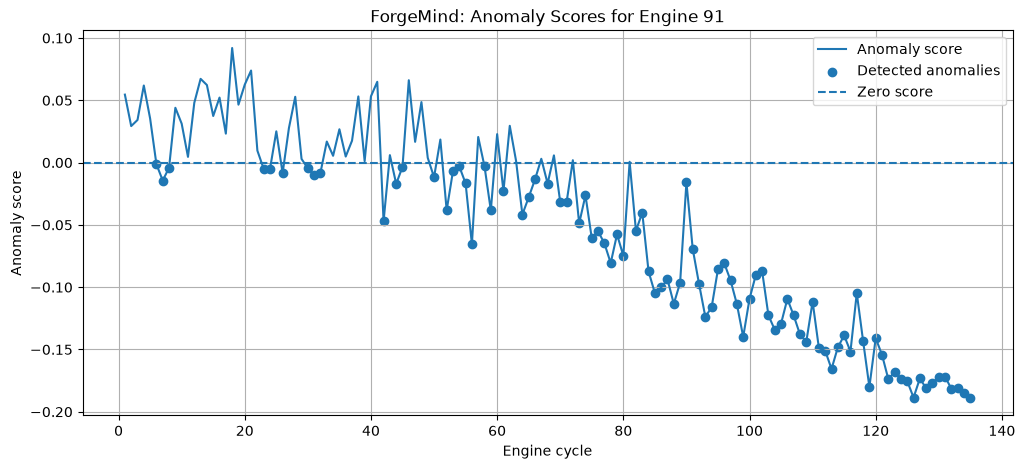

In [14]:
# Select results for Engine 91
engine_id = 91

engine_data = eval_results[
    eval_results["unit_id"] == engine_id
].sort_values("cycle")

# Plot anomaly scores over engine cycles
plt.figure(figsize=(12, 5))

plt.plot(
    engine_data["cycle"],
    engine_data["anomaly_score"],
    label="Anomaly score"
)

# Mark observations classified as anomalies
anomalies = engine_data[engine_data["is_anomaly"]]

plt.scatter(
    anomalies["cycle"],
    anomalies["anomaly_score"],
    label="Detected anomalies"
)

plt.axhline(
    y=0,
    linestyle="--",
    label="Zero score"
)

plt.xlabel("Engine cycle")
plt.ylabel("Anomaly score")
plt.title("ForgeMind: Anomaly Scores for Engine 91")
plt.legend()
plt.grid(True)
plt.show()

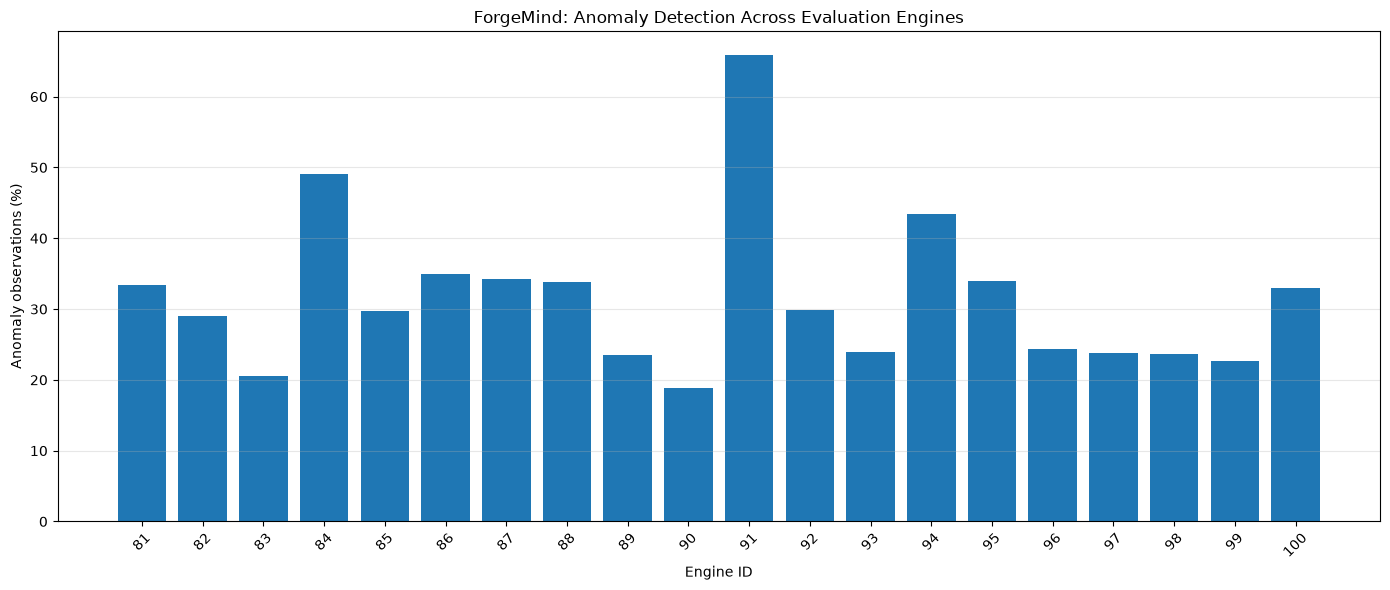

In [15]:
# Plot anomaly percentage for each evaluation engine

plot_data = engine_anomaly_summary.sort_values("unit_id")

plt.figure(figsize=(14, 6))

plt.bar(
    plot_data["unit_id"].astype(str),
    plot_data["anomaly_percentage"]
)

plt.xlabel("Engine ID")
plt.ylabel("Anomaly observations (%)")
plt.title("ForgeMind: Anomaly Detection Across Evaluation Engines")

plt.xticks(rotation=45)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
import joblib
import json
from pathlib import Path

# Define project directories
PROJECT_ROOT = Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "models"

MODEL_DIR.mkdir(parents=True, exist_ok=True)

# Save the trained Isolation Forest model
joblib.dump(
    anomaly_model,
    MODEL_DIR / "isolation_forest_model.joblib"
)

# Save the fitted scaler
joblib.dump(
    baseline_scaler,
    MODEL_DIR / "anomaly_scaler.joblib"
)

# Save metadata required for future predictions
metadata = {
    "model_name": "Isolation Forest",
    "dataset": "NASA C-MAPSS FD001",
    "features": useful_sensors,
    "n_features": len(useful_sensors),
    "n_estimators": anomaly_model.n_estimators,
    "contamination": anomaly_model.contamination,
    "baseline_cycles": 30,
    "training_engines": train_engines,
    "evaluation_engines": eval_engines
}

with open(MODEL_DIR / "anomaly_model_metadata.json", "w") as file:
    json.dump(metadata, file, indent=4)

print("Anomaly detection artifacts saved successfully!")
print("Model:", MODEL_DIR / "isolation_forest_model.joblib")
print("Scaler:", MODEL_DIR / "anomaly_scaler.joblib")
print("Metadata:", MODEL_DIR / "anomaly_model_metadata.json")

Anomaly detection artifacts saved successfully!
Model: /home/ajinkyasingh/Documents/forgemind/models/isolation_forest_model.joblib
Scaler: /home/ajinkyasingh/Documents/forgemind/models/anomaly_scaler.joblib
Metadata: /home/ajinkyasingh/Documents/forgemind/models/anomaly_model_metadata.json


In [18]:
import joblib
import numpy as np
from pathlib import Path

# Locate saved artifacts
PROJECT_ROOT = Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "models"

# Load saved model and scaler
loaded_model = joblib.load(
    MODEL_DIR / "isolation_forest_model.joblib"
)

loaded_scaler = joblib.load(
    MODEL_DIR / "anomaly_scaler.joblib"
)

# Select five evaluation observations
sample_data = eval_df[useful_sensors].head(5)

# Scale and predict using the loaded artifacts
sample_scaled = loaded_scaler.transform(sample_data)
sample_predictions = loaded_model.predict(sample_scaled)
sample_scores = loaded_model.decision_function(sample_scaled)

# Display results
verification_results = eval_df[["unit_id", "cycle"]].head(5).copy()
verification_results["prediction"] = sample_predictions
verification_results["anomaly_score"] = sample_scores
verification_results["status"] = np.where(
    sample_predictions == -1,
    "Anomaly",
    "Normal"
)

print("Saved model loaded successfully!")
print("Predictions generated successfully!")
display(verification_results)

Saved model loaded successfully!
Predictions generated successfully!


,unit_id,cycle,prediction,anomaly_score,status
16138,81,1,1,0.082649,Normal
16139,81,2,1,0.096963,Normal
16140,81,3,1,0.048862,Normal
16141,81,4,1,0.079334,Normal
16142,81,5,1,0.047429,Normal


In [19]:
import json
import joblib
from pathlib import Path

# Locate project model files
PROJECT_ROOT = Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "models"

# Load the saved RUL model and its metadata
rul_model = joblib.load(
    MODEL_DIR / "rul_random_forest_capped.joblib"
)

with open(MODEL_DIR / "rul_model_metadata.json", "r") as file:
    rul_metadata = json.load(file)

# Display model configuration
print("RUL model loaded successfully!")
print("\nRUL model metadata:")
print(json.dumps(rul_metadata, indent=4))

# Check whether the model records its expected feature count
if hasattr(rul_model, "n_features_in_"):
    print("\nExpected input feature count:", rul_model.n_features_in_)

RUL model loaded successfully!

RUL model metadata:
{
    "model_type": "RandomForestRegressor",
    "target": "RUL_capped",
    "rul_cap": 125,
    "n_estimators": 300,
    "max_depth": 15,
    "random_state": 42,
    "features": [
        "op_setting_1",
        "op_setting_2",
        "op_setting_3",
        "sensor_2",
        "sensor_3",
        "sensor_4",
        "sensor_7",
        "sensor_8",
        "sensor_9",
        "sensor_11",
        "sensor_12",
        "sensor_13",
        "sensor_14",
        "sensor_15",
        "sensor_17",
        "sensor_20",
        "sensor_21"
    ],
    "mae": 14.221172887685583,
    "rmse": 19.052641225187145
}

Expected input feature count: 17


In [20]:
import joblib
import json
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "models"

# Load the saved RUL model
rul_model = joblib.load(
    MODEL_DIR / "rul_random_forest_capped.joblib"
)

# Load model metadata
with open(MODEL_DIR / "rul_model_metadata.json", "r") as f:
    rul_metadata = json.load(f)

print("RUL model loaded successfully!")
print("\nExpected number of input features:",
      rul_model.n_features_in_)

print("\nSaved RUL model metadata:")
print(json.dumps(rul_metadata, indent=4))

# Display feature names if available
if hasattr(rul_model, "feature_names_in_"):
    print("\nModel feature names:")
    print(list(rul_model.feature_names_in_))

RUL model loaded successfully!

Expected number of input features: 17

Saved RUL model metadata:
{
    "model_type": "RandomForestRegressor",
    "target": "RUL_capped",
    "rul_cap": 125,
    "n_estimators": 300,
    "max_depth": 15,
    "random_state": 42,
    "features": [
        "op_setting_1",
        "op_setting_2",
        "op_setting_3",
        "sensor_2",
        "sensor_3",
        "sensor_4",
        "sensor_7",
        "sensor_8",
        "sensor_9",
        "sensor_11",
        "sensor_12",
        "sensor_13",
        "sensor_14",
        "sensor_15",
        "sensor_17",
        "sensor_20",
        "sensor_21"
    ],
    "mae": 14.221172887685583,
    "rmse": 19.052641225187145
}

Model feature names:
['op_setting_1', 'op_setting_2', 'op_setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [21]:
import numpy as np
import pandas as pd
import joblib
from pathlib import Path

# Locate saved models
PROJECT_ROOT = Path.cwd().parent
MODEL_DIR = PROJECT_ROOT / "models"

# Load both trained models
rul_model = joblib.load(
    MODEL_DIR / "rul_random_forest_capped.joblib"
)

anomaly_model = joblib.load(
    MODEL_DIR / "isolation_forest_model.joblib"
)

# Load the anomaly detection scaler
anomaly_scaler = joblib.load(
    MODEL_DIR / "anomaly_scaler.joblib"
)

# Load model metadata
import json

with open(MODEL_DIR / "rul_model_metadata.json", "r") as f:
    rul_metadata = json.load(f)

with open(MODEL_DIR / "anomaly_model_metadata.json", "r") as f:
    anomaly_metadata = json.load(f)

rul_features = rul_metadata["features"]
anomaly_features = anomaly_metadata["features"]

print("RUL model loaded:", len(rul_features), "features")
print("Anomaly model loaded:", len(anomaly_features), "features")
print("Combined inference setup initialized!")

RUL model loaded: 17 features
Anomaly model loaded: 15 features
Combined inference setup initialized!


In [22]:
def assess_engine(observation):
    """
    Predict remaining useful life and detect anomalous
    sensor behavior for one engine observation.
    
    observation: A pandas Series or dictionary containing
                 one complete engine observation.
    """

    # Convert input to a DataFrame with one row
    row = pd.DataFrame([observation])

    # Validate required features
    missing_rul = [f for f in rul_features if f not in row.columns]
    missing_anomaly = [
        f for f in anomaly_features if f not in row.columns
    ]

    if missing_rul or missing_anomaly:
        raise ValueError(
            f"Missing RUL features: {missing_rul}; "
            f"Missing anomaly features: {missing_anomaly}"
        )

    # Prepare RUL model input
    rul_input = row[rul_features]

    # Predict capped remaining useful life
    predicted_rul = float(rul_model.predict(rul_input)[0])

    # Prepare anomaly model input
    anomaly_input = row[anomaly_features]
    anomaly_scaled = anomaly_scaler.transform(anomaly_input)

    # Detect unusual sensor behavior
    anomaly_prediction = int(
        anomaly_model.predict(anomaly_scaled)[0]
    )
    anomaly_score = float(
        anomaly_model.decision_function(anomaly_scaled)[0]
    )

    # Return both predictions
    return {
        "predicted_rul_cycles": round(predicted_rul, 2),
        "anomaly_status": (
            "Anomaly" if anomaly_prediction == -1 else "Normal"
        ),
        "anomaly_score": round(anomaly_score, 6)
    }


print("Combined engine assessment function created successfully!")

Combined engine assessment function created successfully!


In [23]:
# Select the first observation from Engine 81
sample_observation = (
    eval_df[eval_df["unit_id"] == 81]
    .sort_values("cycle")
    .iloc[0]
)

# Run the combined assessment
assessment = assess_engine(sample_observation)

print("========== FORGEMIND ENGINE ASSESSMENT ==========")
print("Engine ID:", int(sample_observation["unit_id"]))
print("Engine cycle:", int(sample_observation["cycle"]))
print("Predicted RUL:", assessment["predicted_rul_cycles"], "cycles")
print("Anomaly status:", assessment["anomaly_status"])
print("Anomaly score:", assessment["anomaly_score"])
print("=================================================")

========== FORGEMIND ENGINE ASSESSMENT ==========
Engine ID: 81
Engine cycle: 1
Predicted RUL: 110.93 cycles
Anomaly status: Normal
Anomaly score: 0.082649


In [24]:
# Test ForgeMind on the first 10 observations of Engine 81

engine_samples = (
    eval_df[eval_df["unit_id"] == 81]
    .sort_values("cycle")
    .head(10)
)

results = []

for _, observation in engine_samples.iterrows():
    assessment = assess_engine(observation)

    results.append({
        "unit_id": int(observation["unit_id"]),
        "cycle": int(observation["cycle"]),
        "predicted_rul": assessment["predicted_rul_cycles"],
        "anomaly_status": assessment["anomaly_status"],
        "anomaly_score": assessment["anomaly_score"]
    })

assessment_df = pd.DataFrame(results)

print("ForgeMind: Multi-observation assessment")
display(assessment_df)

print("\nTotal observations assessed:", len(assessment_df))
print(
    "Anomalies detected:",
    (assessment_df["anomaly_status"] == "Anomaly").sum()
)

ForgeMind: Multi-observation assessment


,unit_id,cycle,predicted_rul,anomaly_status,anomaly_score
0,81,1,110.93,Normal,0.082649
1,81,2,107.56,Normal,0.096963
2,81,3,109.95,Normal,0.048862
3,81,4,111.92,Normal,0.079334
4,81,5,103.40,Normal,0.047429
5,81,6,106.14,Normal,0.067517
6,81,7,93.75,Normal,0.076848
7,81,8,118.34,Normal,0.096291
8,81,9,107.96,Normal,0.054808
9,81,10,108.48,Normal,0.076124



Total observations assessed: 10
Anomalies detected: 0


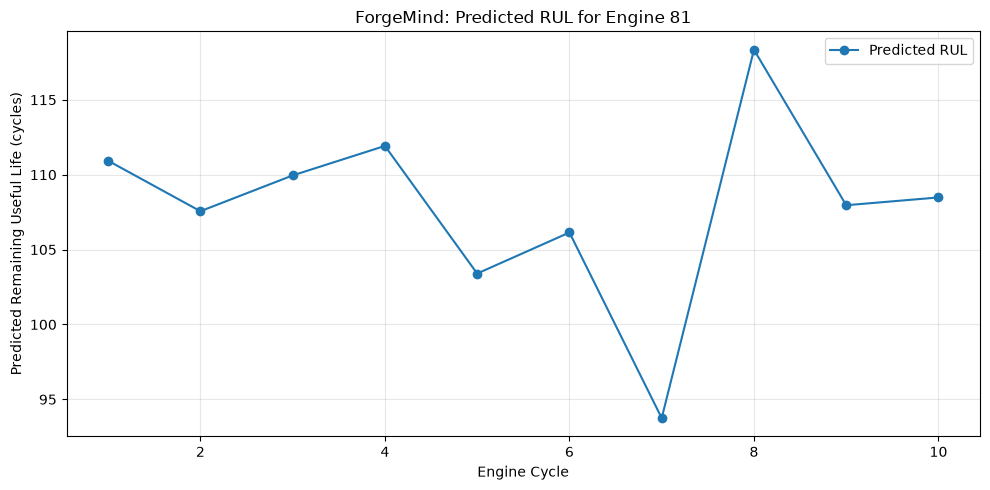

In [26]:
# Plot predicted RUL across the first 10 cycles

plt.figure(figsize=(10, 5))

plt.plot(
    assessment_df["cycle"],
    assessment_df["predicted_rul"],
    marker="o",
    label="Predicted RUL"
)

plt.xlabel("Engine Cycle")
plt.ylabel("Predicted Remaining Useful Life (cycles)")
plt.title("ForgeMind: Predicted RUL for Engine 81")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()